# MapleFreight: Predicting Late Deliveries

This notebook uses only `os`, `warnings`, `numpy`, `pandas`, `matplotlib` and `seaborn`. Everything else (train/test split, cross-validation, logistic regression, metrics) is written by hand in small functions.

## 1. Context
MapleFreight Logistics moves about 8,000 shipments a week across Ontario, Quebec and the Prairies. Its contracts carry on-time guarantees, so every late delivery costs service credits and re-delivery charges. On-time performance has dropped from 94% to 88% this year, and the company only learns a shipment is late when the customer calls.

## 2. Problem statement
Delays are found only after the delivery window has passed. That means service credits are paid, expedited re-deliveries are needed, and complaints reach the account manager before dispatch knows anything is wrong. We need a model that predicts which in-transit shipments will arrive late, early enough for dispatch to re-route or warn the customer.

## 3. Objectives
1. Analyze shipment, route and carrier data to find the main drivers of late delivery.
2. Build a model that classifies whether a shipment will be delivered late, using only information known before delivery.
3. Give actionable recommendations to improve on-time performance.

Target: `delivered_late` (1 = missed the promised window).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42   # makes results repeatable, so every later step uses the same seed

## 4. Data understanding

In [2]:
# Looks for the CSV in a data/ folder first, then the current folder
path = "data/maplefreight_delivery_delay_dataset.csv"
if not os.path.exists(path):
    path = "maplefreight_delivery_delay_dataset.csv"

df = pd.read_csv(path)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (6035, 23)


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
shipment_month,6035.0,6.54,3.45,1.00,4.00,7.00,10.00,12.00
distance_km,6035.0,632.19,319.25,80.50,398.60,571.10,804.85,2556.70
weight_kg,6035.0,6928.25,83755.15,30.00,496.00,827.10,1286.30,2999300.00
num_stops,6035.0,2.48,1.71,0.00,1.00,2.00,4.00,5.00
is_cross_border,6035.0,0.11,0.32,0.00,0.00,0.00,0.00,1.00
scheduled_transit_hours,6035.0,10.50,4.76,1.00,7.06,9.85,13.18,37.40
pickup_delay_minutes,6035.0,20.37,30.62,-20.00,-6.00,18.00,41.00,146.00
driver_experience_years,5825.0,6.50,4.66,0.20,3.20,5.40,8.60,35.00
vehicle_age_years,6035.0,5.49,3.43,0.10,3.00,4.80,7.20,20.00
traffic_index,5914.0,55.15,17.59,5.00,43.30,55.00,67.20,100.00


In [5]:
late_rate = df["delivered_late"].mean()
print(f"Late shipments: {late_rate:.1%}")
print(f"Accuracy of always guessing 'on time': {1 - late_rate:.1%}")

Late shipments: 20.6%
Accuracy of always guessing 'on time': 79.4%


**Finding.** The data has 6,035 rows and 23 columns. About 21% of shipments are late, so a model that always says "on time" is 79% accurate but catches no late shipments. Accuracy is therefore not a useful score here. We will use precision, recall, F1 and PR-AUC instead.

## 5. Exploratory data analysis (EDA)

### 5.1 Data quality problems
The export is raw, so we count each problem before fixing it.

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated shipment_id:", df["shipment_id"].duplicated().sum())
print("service_level spellings:", list(df["service_level"].unique()))
print("Weights above 50,000 kg:", (df["weight_kg"] > 50000).sum())
print()
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Exact duplicate rows: 32
Repeated shipment_id: 35
service_level spellings: ['Standard', 'Express', 'Economy', 'standard', 'economy', 'express']
Weights above 50,000 kg: 40

Missing values:
driver_experience_years    210
weather_condition          150
traffic_index              121
fuel_cost_cad              240
dtype: int64


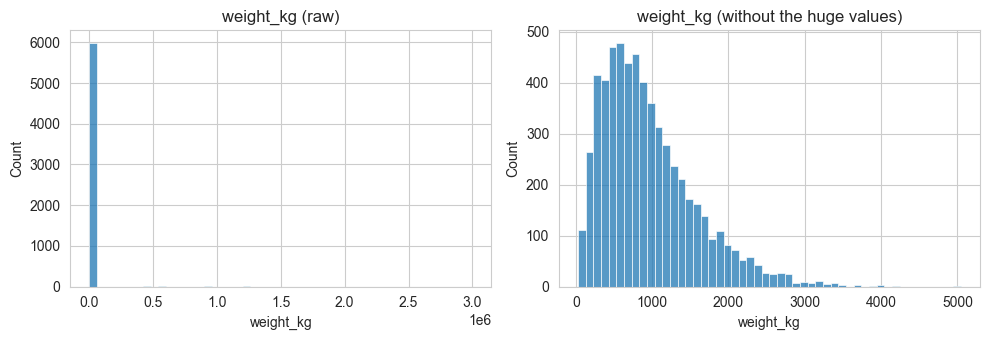

In [7]:
# The huge weights look like grams typed in as kilograms
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df["weight_kg"], bins=50, ax=axes[0]).set_title("weight_kg (raw)")
sns.histplot(df[df["weight_kg"] <= 50000]["weight_kg"], bins=50, ax=axes[1]).set_title("weight_kg (without the huge values)")
plt.tight_layout()
plt.show()

**Findings**
- 32 exact duplicate rows, and 3 more shipment IDs that repeat with different values.
- `service_level` has mixed capitalisation (`Standard` and `standard`).
- 40 weights are around 1,000 times too large (170,000 to 3,000,000 kg), which looks like grams entered as kilograms.
- Four columns have missing values: `driver_experience_years`, `weather_condition`, `traffic_index`, `fuel_cost_cad`.

### 5.2 Which columns drive late delivery?

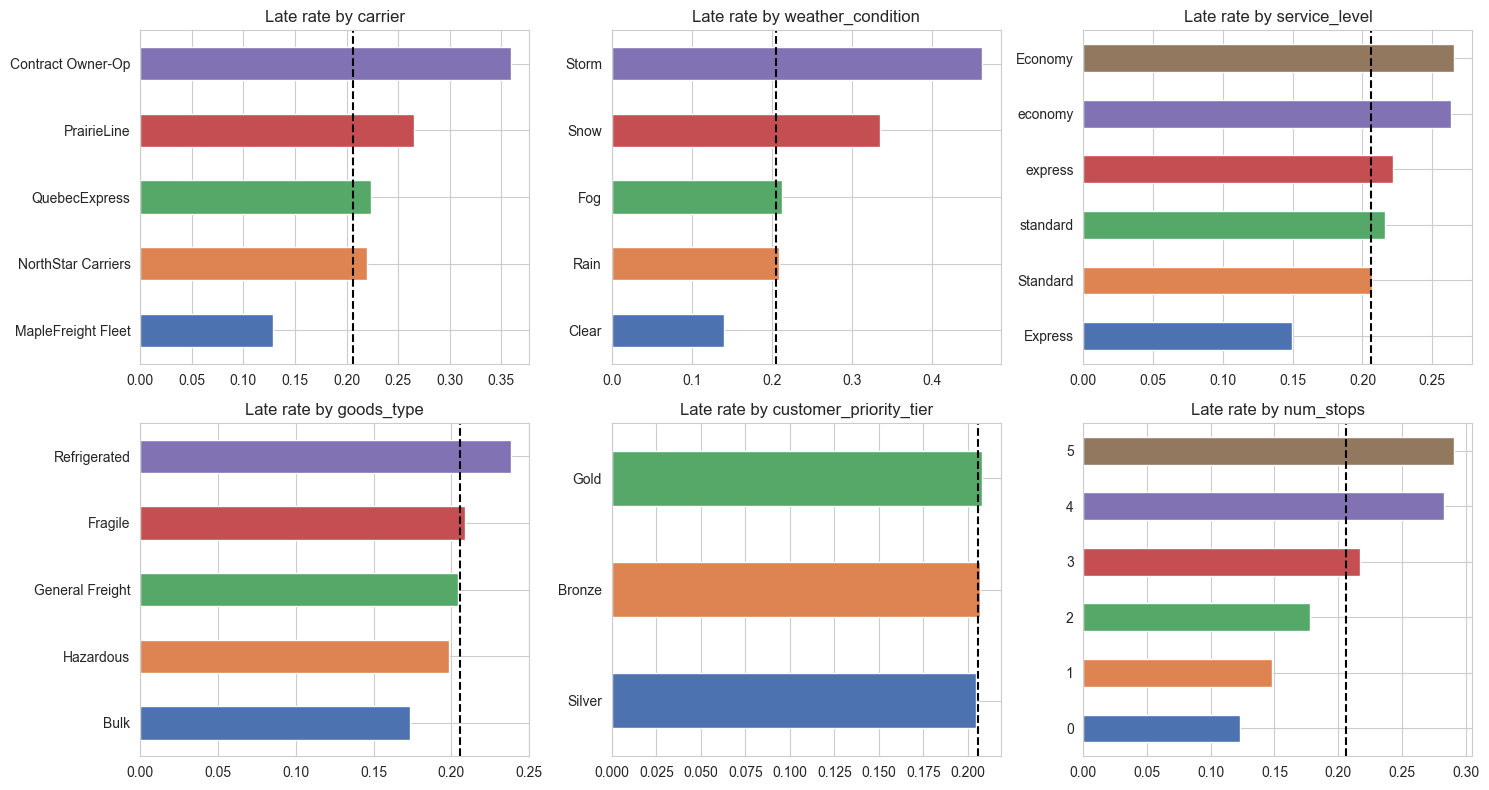

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["carrier", "weather_condition", "service_level",
                                  "goods_type", "customer_priority_tier", "num_stops"]):
    rate = df.groupby(col)["delivered_late"].mean().sort_values()
    rate.plot.barh(ax=ax, color=sns.color_palette("deep", len(rate)))
    ax.axvline(late_rate, color="black", linestyle="--")   # dashed line = overall late rate
    ax.set_title("Late rate by " + col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

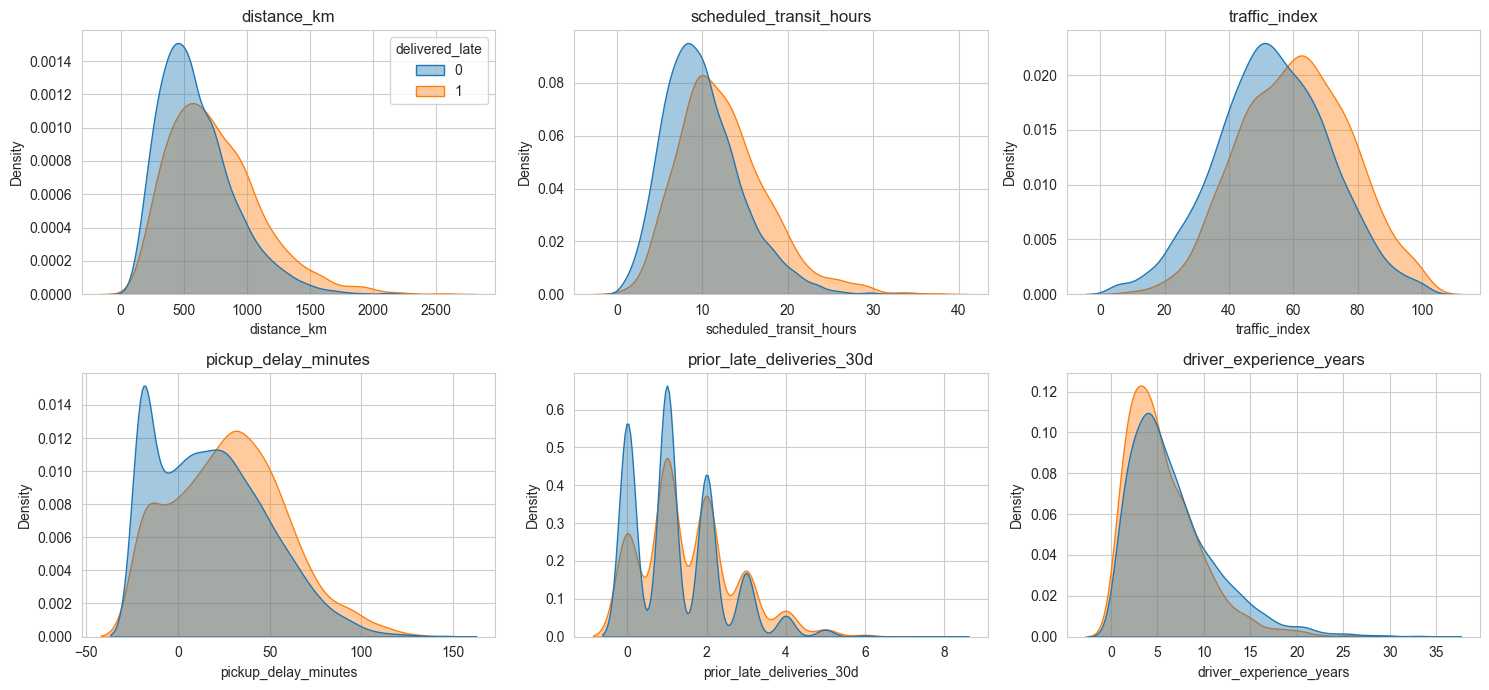

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ["distance_km", "scheduled_transit_hours", "traffic_index",
                                  "pickup_delay_minutes", "prior_late_deliveries_30d", "driver_experience_years"]):
    sns.kdeplot(data=df, x=col, hue="delivered_late", common_norm=False, fill=True, alpha=0.4, ax=ax, legend=(col == "distance_km"))
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [10]:
# Carrier and weather together
print(df.pivot_table(index="carrier", columns="weather_condition", values="delivered_late", aggfunc="mean").round(2))
print()

# Late rate by how late the pickup was
pickup_group = pd.cut(df["pickup_delay_minutes"], [-100, 0, 30, 60, 1000],
                      labels=["early/on time", "0-30 min", "30-60 min", "over 60 min"])
print(df.groupby(pickup_group)["delivered_late"].mean().round(3))

weather_condition   Clear   Fog  Rain  Snow  Storm
carrier                                           
Contract Owner-Op    0.29  0.33  0.36  0.55   0.56
MapleFreight Fleet   0.07  0.15  0.13  0.22   0.38
NorthStar Carriers   0.16  0.24  0.22  0.35   0.43
PrairieLine          0.17  0.32  0.26  0.41   0.56
QuebecExpress        0.16  0.19  0.23  0.40   0.61

pickup_delay_minutes
early/on time    0.146
0-30 min         0.195
30-60 min        0.268
over 60 min      0.265
Name: delivered_late, dtype: float64


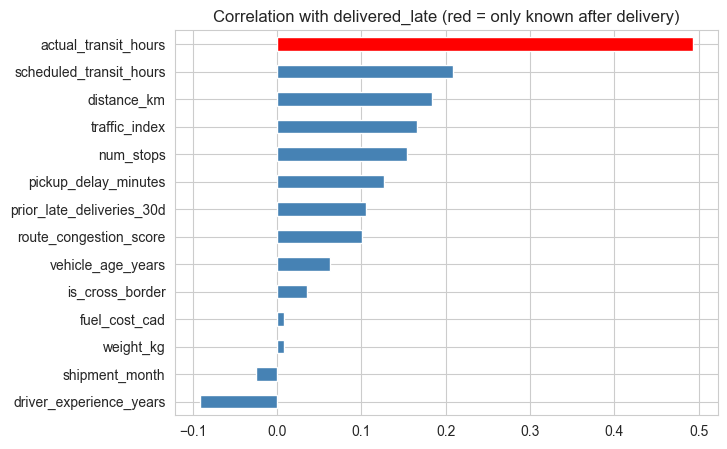

In [11]:
# Correlation of every numeric column with the target
numeric = df.select_dtypes("number").drop(columns="delivered_late")
corr = numeric.corrwith(df["delivered_late"]).sort_values()

colors = ["red" if name == "actual_transit_hours" else "steelblue" for name in corr.index]
corr.plot.barh(color=colors, figsize=(7, 5), title="Correlation with delivered_late (red = only known after delivery)")
plt.show()

**Findings**
- **Carrier:** contract owner-operators are late about 36% of the time, against about 13% for the MapleFreight fleet. The gap holds in every kind of weather.
- **Weather:** about 14% late in clear weather, 33% in snow and 46% in storms.
- **Route:** more stops, longer distance and longer scheduled transit all go with more late deliveries.
- **Pickup:** shipments picked up more than 30 minutes late are late about 27% of the time, against about 15% for early or on-time pickups.
- **Customer priority tier** makes no difference to the late rate.
- **Data leakage:** `actual_transit_hours` has a correlation of about 0.49 with the target, more than twice any other column. It is recorded on delivery, so it is not known while the shipment is in transit. Using it would make a model look great and be useless in practice, so we will not use it.

## 6. Data preprocessing

In [12]:
rows_before = len(df)

df = df.drop_duplicates()                                    # remove exact copies
df = df.drop_duplicates(subset="shipment_id", keep="first")  # repeated IDs: keep the first record
df["service_level"] = df["service_level"].str.title()        # standardise spelling
big = df["weight_kg"] > 50000
df.loc[big, "weight_kg"] = df.loc[big, "weight_kg"] / 1000   # grams -> kilograms
df = df.reset_index(drop=True)

print(f"Rows: {rows_before} -> {len(df)}")
print("Weight range now:", df["weight_kg"].min(), "to", df["weight_kg"].max())
print("service_level:", list(df["service_level"].unique()))
print(f"Late rate after cleaning: {df['delivered_late'].mean():.1%}")

Rows: 6035 -> 6000
Weight range now: 30.0 to 5044.0
service_level: ['Standard', 'Express', 'Economy']
Late rate after cleaning: 20.6%


**Finding.** We removed 35 duplicate rows (6,035 to 6,000), fixed the spelling of `service_level`, and divided the 40 oversized weights by 1,000, which puts them in the normal range (30 to about 5,000 kg). Missing values are not filled here. They are filled in section 8 using only the training data, so the test data cannot influence the fill values.

## 7. Feature engineering
We add three simple features that are known at dispatch. Section 9 tests whether they actually help.

In [13]:
df["is_winter"] = df["shipment_month"].isin([12, 1, 2]).astype(int)    # Dec, Jan, Feb
df["pickup_over_30"] = (df["pickup_delay_minutes"] > 30).astype(int)   # started more than 30 minutes late
df["stops_per_hour"] = df["num_stops"] / df["scheduled_transit_hours"] # how busy the promised window is

df[["is_winter", "pickup_over_30", "stops_per_hour", "delivered_late"]].corr()["delivered_late"].round(3)

is_winter         0.049
pickup_over_30    0.112
stops_per_hour    0.036
delivered_late    1.000
Name: delivered_late, dtype: float64

**Finding.** `pickup_over_30` has the strongest link to the target (about 0.11). The other two are weak on their own. Whether they add anything to the model is tested later.

## 8. Data preparation
**Plan**
1. Choose the input columns. We leave out `delivered_late` (the answer), `actual_transit_hours` (leakage), `shipment_id`, and the two city columns (distance, stops and transit time already describe the route, and the 17 city columns add noise).
2. Split the data 80/20 into train and test, keeping the same late rate in both. The test set stays untouched until the final evaluation.
3. Turn the data into numbers: fill missing values, one-hot encode categories and scale numeric columns. All fill and scaling values come from the training data only.

In [14]:
drop_cols = ["delivered_late", "actual_transit_hours", "shipment_id", "origin_city", "destination_city"]
new_features = ["is_winter", "pickup_over_30", "stops_per_hour"]

feature_cols = [c for c in df.columns if c not in drop_cols]
original_cols = [c for c in feature_cols if c not in new_features]

y = df["delivered_late"].to_numpy()

def stratified_split(y, test_size=0.2):
    # Splits each class (0 and 1) separately so train and test keep the same late rate
    rng = np.random.default_rng(RANDOM_STATE)
    is_test = np.zeros(len(y), dtype=bool)
    for cls in [0, 1]:
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        is_test[idx[:int(round(len(idx) * test_size))]] = True
    return is_test

is_test = stratified_split(y)
train_df = df[~is_test].reset_index(drop=True)
test_df = df[is_test].reset_index(drop=True)
y_train = y[~is_test]
y_test = y[is_test]

print("Train:", train_df.shape, f"late = {y_train.mean():.1%}")
print("Test: ", test_df.shape, f"late = {y_test.mean():.1%}")

Train: (4800, 26) late = 20.6%
Test:  (1200, 26) late = 20.6%


In [15]:
def build_features(train, other, cols):
    # Turns the chosen columns into number matrices. Everything is learned from `train` only.
    num_cols = [c for c in cols if pd.api.types.is_numeric_dtype(train[c])]
    cat_cols = [c for c in cols if c not in num_cols]
    train, other = train[cols].copy(), other[cols].copy()

    for c in num_cols:                         # missing numbers -> median of the training data
        median = train[c].median()
        train[c] = train[c].fillna(median)
        other[c] = other[c].fillna(median)
    for c in cat_cols:                         # missing categories -> "Unknown"
        train[c] = train[c].fillna("Unknown")
        other[c] = other[c].fillna("Unknown")

    mean, std = train[num_cols].mean(), train[num_cols].std().replace(0, 1)
    train_num = (train[num_cols] - mean) / std  # scale: mean 0, spread 1
    other_num = (other[num_cols] - mean) / std

    train_cat = pd.get_dummies(train[cat_cols], dtype=float)                 # one-hot encoding
    other_cat = pd.get_dummies(other[cat_cols], dtype=float).reindex(columns=train_cat.columns, fill_value=0.0)

    A_train = pd.concat([train_num, train_cat], axis=1)
    A_other = pd.concat([other_num, other_cat], axis=1)
    return A_train.to_numpy(float), A_other.to_numpy(float), list(A_train.columns)

A_train, A_test, names = build_features(train_df, test_df, original_cols)
print("Model input shape (train):", A_train.shape, "| (test):", A_test.shape)
print("No missing values left:", not np.isnan(A_train).any() and not np.isnan(A_test).any())

Model input shape (train): (4800, 35) | (test): (1200, 35)
No missing values left: True


**Finding.** The 80/20 split keeps the late rate at 20.6% in both parts. The original columns become 35 model inputs after one-hot encoding and scaling, with no missing values left.

## 9. Data modelling
**Model:** logistic regression, written by hand. It gives each shipment a risk score between 0 and 1. It is fitted with Newton's method and a small penalty (`l2`) that keeps the coefficients from growing too large.

**Handling imbalance:** with `class_weight="balanced"`, each late shipment counts about 2.4 times as much as an on-time one, so the model cannot ignore the minority class.

**Models compared** with 5-fold cross-validation on the training data, scored by PR-AUC (average precision), which stays honest when classes are imbalanced:
1. **Baseline:** plain logistic regression, no class weights, original columns.
2. Balanced logistic regression, original columns.
3. Balanced logistic regression, original columns plus the three new features.

In [16]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def fit_logistic(A, y, class_weight=None, l2=1.0, n_iter=30):
    # Logistic regression fitted with Newton's method. Column 0 of X is the intercept (not penalised).
    X = np.column_stack([np.ones(len(A)), A])
    weight = np.ones(len(y))
    if class_weight == "balanced":
        n, n_late = len(y), y.sum()
        weight = np.where(y == 1, n / (2 * n_late), n / (2 * (n - n_late)))
    penalty = l2 * np.eye(X.shape[1])
    penalty[0, 0] = 0
    beta = np.zeros(X.shape[1])
    for _ in range(n_iter):
        p = sigmoid(X @ beta)
        gradient = X.T @ (weight * (p - y)) + penalty @ beta
        hessian = X.T @ (X * (weight * p * (1 - p))[:, None]) + penalty
        beta = beta - np.linalg.solve(hessian, gradient)
    return beta

def predict_proba(A, beta):
    return sigmoid(np.column_stack([np.ones(len(A)), A]) @ beta)

In [17]:
def average_precision(y, prob):
    # PR-AUC: average of the precision at every late shipment, ranking by risk score
    order = np.argsort(-prob, kind="mergesort")
    y_sorted = y[order]
    precision_at_k = np.cumsum(y_sorted) / np.arange(1, len(y) + 1)
    return (precision_at_k * y_sorted).sum() / y.sum()

def roc_auc(y, prob):
    ranks = pd.Series(prob).rank().to_numpy()
    n_late, n_ok = y.sum(), (1 - y).sum()
    return (ranks[y == 1].sum() - n_late * (n_late + 1) / 2) / (n_late * n_ok)

def make_folds(y, k=5):
    # Gives every row a fold number 0..k-1, keeping the late rate similar in each fold
    rng = np.random.default_rng(RANDOM_STATE)
    folds = np.zeros(len(y), dtype=int)
    for cls in [0, 1]:
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        for f, part in enumerate(np.array_split(idx, k)):
            folds[part] = f
    return folds

def cross_val_probs(cols, class_weight, k=5):
    # Each training shipment gets a risk score from a model that never saw it
    folds = make_folds(y_train, k)
    probs = np.zeros(len(y_train))
    for f in range(k):
        fit_rows, val_rows = folds != f, folds == f
        A_fit, A_val, _ = build_features(train_df[fit_rows], train_df[val_rows], cols)
        beta = fit_logistic(A_fit, y_train[fit_rows], class_weight)
        probs[val_rows] = predict_proba(A_val, beta)
    fold_scores = [average_precision(y_train[folds == f], probs[folds == f]) for f in range(k)]
    return probs, fold_scores

In [18]:
model_setups = {
    "Baseline: logistic regression (no class weights)": (original_cols, None),
    "Logistic regression (balanced)": (original_cols, "balanced"),
    "Logistic regression (balanced) + new features": (feature_cols, "balanced"),
}

rows = []
oof_probs = {}
for name, (cols, weight) in model_setups.items():
    probs, fold_scores = cross_val_probs(cols, weight)
    oof_probs[name] = probs
    rows.append({"model": name, "CV PR-AUC (mean)": np.mean(fold_scores), "spread (std)": np.std(fold_scores)})

cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,CV PR-AUC (mean),spread (std)
model,,
Baseline: logistic regression (no class weights),0.574,0.020
Logistic regression (balanced),0.574,0.019
Logistic regression (balanced) + new features,0.574,0.019


**Finding.** All three models score exactly the same in cross-validation (PR-AUC 0.574, with about 0.02 spread between folds). Two things explain this. First, class weights do not change how shipments are *ranked*, they only shift the scores upward so that more shipments cross the 0.5 cut-off, so PR-AUC cannot tell the baseline from the balanced model; the difference shows up in recall in section 10. Second, the three new features add nothing the original columns do not already contain. We therefore pick the **simplest option: balanced logistic regression on the original columns**, which is also the easiest to explain.

## 10. Model evaluation
We fit the baseline and the chosen final model on the full training set and score both once on the test set. We report precision, recall, F1 and a confusion matrix, as well as PR-AUC and ROC-AUC.

In [19]:
final_name = "Logistic regression (balanced)"             # chosen from the table above
baseline_name = "Baseline: logistic regression (no class weights)"

def fit_and_predict(name):
    cols, weight = model_setups[name]
    A_fit, A_new, feature_names = build_features(train_df, test_df, cols)
    beta = fit_logistic(A_fit, y_train, weight)
    return predict_proba(A_new, beta), beta, feature_names

prob_base, _, _ = fit_and_predict(baseline_name)
prob_final, beta_final, final_names = fit_and_predict(final_name)

def confusion(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    return tn, fp, fn, tp

def score(name, y_true, prob, threshold=0.5):
    tn, fp, fn, tp = confusion(y_true, prob, threshold)
    precision = tp / max(tp + fp, 1)
    recall = tp / (tp + fn)
    return {"model": name, "threshold": threshold,
            "accuracy": (tp + tn) / len(y_true),
            "precision": precision, "recall": recall,
            "F1": 2 * precision * recall / max(precision + recall, 1e-9),
            "PR-AUC": average_precision(y_true, prob), "ROC-AUC": roc_auc(y_true, prob)}

always_on_time = np.zeros(len(y_test))
table = pd.DataFrame([score("Always on time", y_test, always_on_time),
                      score("Baseline", y_test, prob_base),
                      score("Final", y_test, prob_final)]).set_index("model").round(3)
table

,threshold,accuracy,precision,recall,F1,PR-AUC,ROC-AUC
model,,,,,,,
Always on time,0.5,0.794,0.000,0.000,0.000,0.204,0.500
Baseline,0.5,0.831,0.696,0.316,0.435,0.586,0.824
Final,0.5,0.742,0.426,0.729,0.537,0.586,0.824


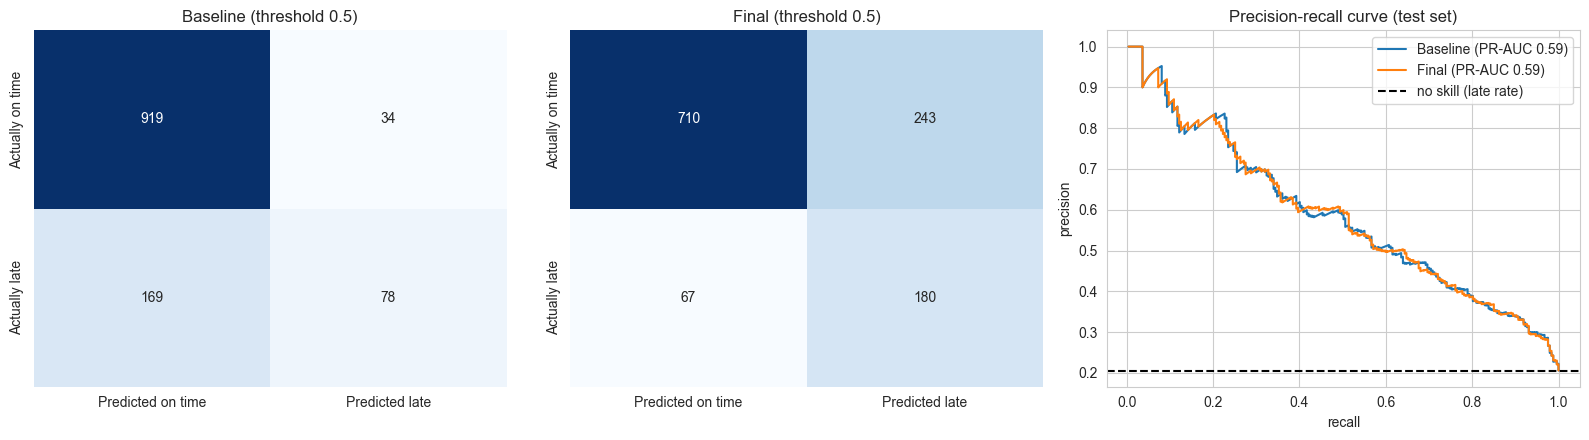

In [20]:
def plot_confusion(ax, y_true, prob, threshold, title):
    tn, fp, fn, tp = confusion(y_true, prob, threshold)
    sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted on time", "Predicted late"], yticklabels=["Actually on time", "Actually late"])
    ax.set_title(title)

def pr_curve(y_true, prob):
    order = np.argsort(-prob, kind="mergesort")
    y_sorted = y_true[order]
    tp = np.cumsum(y_sorted)
    return tp / np.arange(1, len(y_true) + 1), tp / y_true.sum()   # precision, recall

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_confusion(axes[0], y_test, prob_base, 0.5, "Baseline (threshold 0.5)")
plot_confusion(axes[1], y_test, prob_final, 0.5, "Final (threshold 0.5)")
for name, prob in [("Baseline", prob_base), ("Final", prob_final)]:
    precision, recall = pr_curve(y_test, prob)
    axes[2].plot(recall, precision, label=f"{name} (PR-AUC {average_precision(y_test, prob):.2f})")
axes[2].axhline(y_test.mean(), color="black", linestyle="--", label="no skill (late rate)")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
axes[2].set_title("Precision-recall curve (test set)")
axes[2].legend()
plt.tight_layout()
plt.show()

**Finding.** The baseline looks good on accuracy (83%) but catches only about a third of late shipments (recall 0.32), because with just 21% late shipments it rarely scores above 0.5. The balanced model catches 73% of them, but precision falls from 0.70 to 0.43, so more than half of its alerts at 0.5 would be false alarms. PR-AUC (0.586) and ROC-AUC (0.824) are identical for both, which confirms the models rank shipments the same way. The real gain comes from handling the imbalance and choosing the threshold, not from a cleverer model. The ROC-AUC of 0.82 means the model ranks risky shipments reasonably well, but it cannot be both very precise and very sensitive.

### Choosing the alert threshold
The risk score runs from 0 to 1, and the threshold is the score above which we would warn dispatch. Two mistakes compete: missing a late shipment (service credits and re-delivery) and a false alarm (a few minutes of dispatch time).

**The dollar figures below are assumptions, not MapleFreight data.** Replace them with real numbers from finance. We also require that **at least half of the alerts are real late shipments**, otherwise dispatch would start ignoring them. To avoid peeking at the test set, the threshold is chosen from the cross-validated training predictions.

Cheapest threshold ignoring precision: 0.49 (precision 0.43, alerts on 36% of shipments)
Chosen threshold (precision >= 50%): 0.63 (precision 0.51, recall 0.59, alerts on 24% of shipments)
Expected cost per shipment: $50.72 vs $61.69 with no system


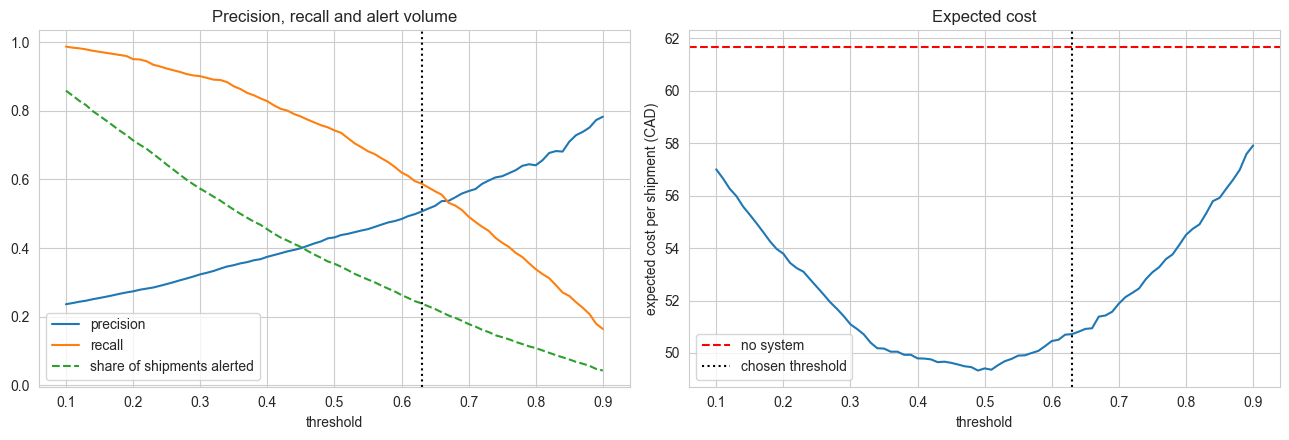

In [21]:
COST_MISSED_LATE = 300   # assumed cost (CAD) of a late shipment nobody warned about
COST_ALERT = 30          # assumed cost (CAD) of dispatch reviewing one alert
SAVE_RATE = 0.5          # assumed share of flagged late shipments dispatch can save in time
MIN_PRECISION = 0.50

oof = oof_probs[final_name]
rows = []
for t in np.arange(0.10, 0.91, 0.01):
    flagged = oof >= t
    tp = (flagged & (y_train == 1)).sum()
    fp = (flagged & (y_train == 0)).sum()
    fn = (~flagged & (y_train == 1)).sum()
    cost = fn * COST_MISSED_LATE + tp * COST_MISSED_LATE * (1 - SAVE_RATE) + (tp + fp) * COST_ALERT
    rows.append({"threshold": round(t, 2), "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn),
                 "share_alerted": flagged.mean(), "cost_per_shipment": cost / len(y_train)})
sweep = pd.DataFrame(rows)

cheapest = sweep.loc[sweep["cost_per_shipment"].idxmin()]
allowed = sweep[sweep["precision"] >= MIN_PRECISION]
chosen = allowed.loc[allowed["cost_per_shipment"].idxmin()]
THRESHOLD = float(chosen["threshold"])
no_system_cost = y_train.mean() * COST_MISSED_LATE

print(f"Cheapest threshold ignoring precision: {cheapest['threshold']} "
      f"(precision {cheapest['precision']:.2f}, alerts on {cheapest['share_alerted']:.0%} of shipments)")
print(f"Chosen threshold (precision >= {MIN_PRECISION:.0%}): {THRESHOLD} "
      f"(precision {chosen['precision']:.2f}, recall {chosen['recall']:.2f}, alerts on {chosen['share_alerted']:.0%} of shipments)")
print(f"Expected cost per shipment: ${chosen['cost_per_shipment']:.2f} vs ${no_system_cost:.2f} with no system")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sweep["threshold"], sweep["precision"], label="precision")
axes[0].plot(sweep["threshold"], sweep["recall"], label="recall")
axes[0].plot(sweep["threshold"], sweep["share_alerted"], label="share of shipments alerted", linestyle="--")
axes[0].axvline(THRESHOLD, color="black", linestyle=":")
axes[0].set_xlabel("threshold")
axes[0].legend()
axes[0].set_title("Precision, recall and alert volume")
axes[1].plot(sweep["threshold"], sweep["cost_per_shipment"])
axes[1].axhline(no_system_cost, color="red", linestyle="--", label="no system")
axes[1].axvline(THRESHOLD, color="black", linestyle=":", label="chosen threshold")
axes[1].set_xlabel("threshold")
axes[1].set_ylabel("expected cost per shipment (CAD)")
axes[1].legend()
axes[1].set_title("Expected cost")
plt.tight_layout()
plt.show()

**Finding.** If we only minimise the assumed cost, the best threshold is about 0.49, which alerts on 36% of shipments (roughly 2,900 a week) and only 43% of those alerts are real. That is too noisy to use. Adding the rule that at least half of alerts must be real gives **a threshold of 0.63**: on the training data, precision 0.51, recall 0.59, and about 24% of shipments flagged (roughly 1,900 a week). The cost saving shown (about 18%) depends entirely on the assumed dollar figures and the assumed 50% save rate, so replace them with real numbers from finance.

accuracy  precision  recall     F1  PR-AUC  ROC-AUC
model    threshold                                                     
Baseline 0.50          0.831      0.696   0.316  0.435   0.586    0.824
Final    0.50          0.742      0.426   0.729  0.537   0.586    0.824
         0.63          0.802      0.517   0.567  0.541   0.586    0.824

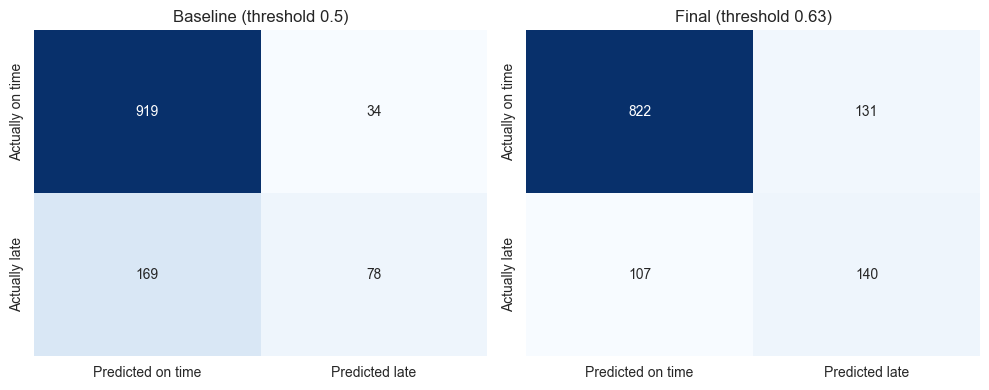

Caught 140 of 247 late shipments, with 131 false alarms among 953 on-time shipments.


In [22]:
final_table = pd.DataFrame([score("Baseline", y_test, prob_base, 0.5),
                            score("Final", y_test, prob_final, 0.5),
                            score("Final", y_test, prob_final, THRESHOLD)]).set_index(["model", "threshold"]).round(3)
display(final_table)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion(axes[0], y_test, prob_base, 0.5, "Baseline (threshold 0.5)")
plot_confusion(axes[1], y_test, prob_final, THRESHOLD, f"Final (threshold {THRESHOLD})")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion(y_test, prob_final, THRESHOLD)
print(f"Caught {tp} of {tp + fn} late shipments, with {fp} false alarms among {tn + fp} on-time shipments.")

**Finding.** On the test set at threshold 0.63 the final model catches **140 of 247 late shipments (recall 0.57)** with precision 0.52 and F1 0.54, and raises 271 alerts per 1,200 shipments (about 23%). At the same time the baseline at 0.5 catches only about 78 late shipments. The result on the test set is close to what the training data predicted (precision 0.51, recall 0.59), which suggests the threshold choice is stable. The model still misses 107 late shipments and raises 131 false alarms, so it supports dispatch decisions rather than replacing them.

## 11. Model explainability and recommendations

In [24]:
if os.path.exists(".env"):
    with open(".env") as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                key, value = line.split("=", 1)
                os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))

webhook_found = bool(os.environ.get("SLACK_WEBHOOK_URL"))
print("Webhook found in environment:", webhook_found)

Webhook found in environment: True


In [25]:
scored = test_df[["shipment_id", "destination_city", "carrier"]].copy()
scored["risk"] = prob_final

alerts = scored[scored["risk"] >= THRESHOLD].sort_values("risk", ascending=False).reset_index(drop=True)

print(f"{len(alerts)} of {len(scored)} shipments are at or above the threshold of {THRESHOLD}")
alerts.head(5)

271 of 1200 shipments are at or above the threshold of 0.63


,shipment_id,destination_city,carrier,risk
0,SHP-105192,Ottawa ON,Contract Owner-Op,0.991676
1,SHP-100936,Calgary AB,PrairieLine,0.986454
2,SHP-100079,Regina SK,Contract Owner-Op,0.979490
3,SHP-103230,Regina SK,Contract Owner-Op,0.979071
4,SHP-102910,Edmonton AB,QuebecExpress,0.978492


In [26]:
TOP_N = 5

lines = [f":rotating_light: *{len(alerts)} of {len(scored)} in-transit shipments are at high risk of being late*"]
lines.append(f"Top {min(TOP_N, len(alerts))} by risk score:")
for i, row in enumerate(alerts.head(TOP_N).itertuples(), start=1):
    lines.append(f"{i}. {row.shipment_id} | {row.destination_city} | {row.carrier} | risk {row.risk * 100:.0f}/100")
lines.append("Re-route or warn the customer before the delivery window closes.")

message = "\n".join(lines)
print(message)

:rotating_light: *271 of 1200 in-transit shipments are at high risk of being late*
Top 5 by risk score:
1. SHP-105192 | Ottawa ON | Contract Owner-Op | risk 99/100
2. SHP-100936 | Calgary AB | PrairieLine | risk 99/100
3. SHP-100079 | Regina SK | Contract Owner-Op | risk 98/100
4. SHP-103230 | Regina SK | Contract Owner-Op | risk 98/100
5. SHP-102910 | Edmonton AB | QuebecExpress | risk 98/100
Re-route or warn the customer before the delivery window closes.


In [27]:
safe_text = message.replace("\\", "\\\\").replace('"', '\\"').replace("\n", "\\n")
payload = '{"text": "' + safe_text + '"}'

with open("slack_payload.json", "w") as f:
    f.write(payload)

print(payload[:150] + " ...")

{"text": ":rotating_light: *271 of 1200 in-transit shipments are at high risk of being late*\nTop 5 by risk score:\n1. SHP-105192 | Ottawa ON | Contra ...


In [28]:
def send_to_slack():
    if not os.environ.get("SLACK_WEBHOOK_URL"):
        print("DRY RUN: no webhook found, so nothing was sent.")
        print("Create the .env file first, then run this notebook again.")
        return None

    url_variable = "%SLACK_WEBHOOK_URL%" if os.name == "nt" else "$SLACK_WEBHOOK_URL"
    command = (f'curl -s --max-time 15 -X POST -H "Content-type: application/json" '
               f'--data @slack_payload.json "{url_variable}"')
    answer = os.popen(command).read().strip()

    if answer == "ok":
        print("Sent. Slack replied: ok")
    else:
        print("Slack did not accept the message. Reply:", answer or "(no reply, check your internet connection)")
    return answer

slack_reply = send_to_slack()

Sent. Slack replied: ok


In [29]:
if os.path.exists("slack_payload.json"):
    os.remove("slack_payload.json")

### 11.1 What drives the predictions?
The final model is a logistic regression, so we can read its coefficients directly. A positive number pushes a shipment towards "late"; a negative number pushes it towards "on time". Numeric inputs are scaled, so their sizes can be compared with each other.

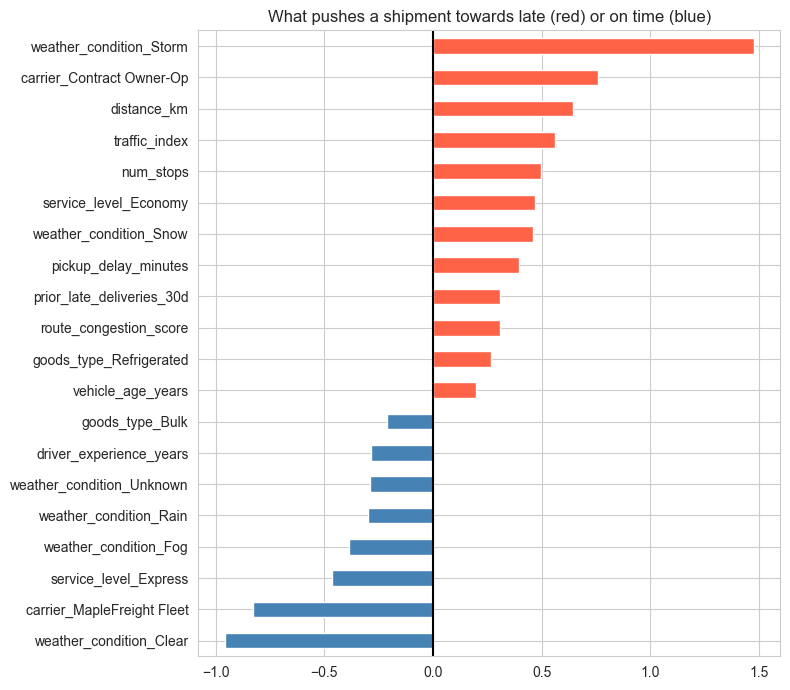

In [23]:
coef = pd.Series(beta_final[1:], index=final_names).sort_values()   # beta_final[0] is the intercept

top = pd.concat([coef.head(8), coef.tail(12)])
top.plot.barh(figsize=(8, 7), color=["tomato" if v > 0 else "steelblue" for v in top],
              title="What pushes a shipment towards late (red) or on time (blue)")
plt.axvline(0, color="black")
plt.tight_layout()
plt.show()

**Finding.** The coefficients agree with the EDA. The strongest pushes towards late are **storm weather** (by far the largest), **contract owner-operator carriers**, **longer distance**, **heavier traffic**, **more stops**, **Economy service**, **snow** and **a late pickup**. The strongest pushes towards on time are **clear weather**, the **MapleFreight fleet**, **Express service** and **experienced drivers**. Coefficients show direction and relative size, but they do not prove cause and effect.

### 11.2 Recommendations

1. **Fix the carrier gap first.** Contract owner-operators are late 36% of the time against 13% for the MapleFreight fleet, and the gap is there in every kind of weather. Review their contract terms and onboarding, and avoid them for Express freight where possible.
2. **Plan for weather.** Late rates are 14% in clear weather, 33% in snow and 46% in storms. When the forecast is snow or storm, add time to the promised window, use the carriers with the best winter record, and warn customers at booking.
3. **Treat a late pickup as an early warning.** Shipments picked up more than 30 minutes late are late about 27% of the time, against about 15% for early or on-time pickups. Check these shipments at pickup, while there is still time to re-plan the route.
4. **Quote realistic windows for long, multi-stop and Economy shipments.** Shipments with 3 to 5 stops are late about 26% of the time (12% with no stops), and Economy is late 27% against 15% for Express. Adding slack to these promises costs less than paying credits.
5. **Use the model as a ranked watch-list.** About 23% of shipments get flagged at threshold 0.63, so dispatch should start from the highest risk scores and go further down only as capacity allows. Re-tune the threshold once finance confirms the real cost of a missed delivery.
6. **Improve the data.** Confirm what `is_cross_border` means (every flagged shipment has a Canadian destination), add a pickup date so the model can be tested over time, and add a live ETA or GPS feed. Better live signals are likely to help more than a more complex model.

**Limitations.** One random split of 6,000 shipments, no date column, assumed cost figures, and a risk score that is not an exact probability. Re-check the results on live data before relying on the cost savings.